# UNSW-NB15 EDA

## Основная постановка

Пока рассматриваем бинарную задачу классификации

Основная целевая переменная:

- `label = 0` — нормальный трафик;
- `label = 1` — атака.

`attack_cat` содержит тип атаки и рассматривается как дополнительная целевая переменная.  

# 1. Импорт библиотек и загрузка данных

Ноутбук ищет файлы рядом с собой и в `./data/`:

- `UNSW_NB15_training-set.parquet`
- `UNSW_NB15_testing-set.parquet`

Также поддерживаются `.csv`-версии с теми же именами.

In [1]:
import sys
import platform
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

from scipy.stats import chi2_contingency

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)

Python: 3.12.14
Executable: /home/andrei/miniconda3/envs/ml-ds/bin/python
Platform: Linux-7.0.0-34-generic-x86_64-with-glibc2.43
NumPy: 2.5.3
Pandas: 3.0.5
Seaborn: 0.13.2


In [37]:
path_train = ('UNSW_NB15_training-set.parquet')
path_test = ('UNSW_NB15_testing-set.parquet')

train = pd.read_parquet(path_train)
test = pd.read_parquet(path_test)

# 2. Общая характеристика данных

Сначала рассматриваем исходные данные без какой-либо очистки.

Для общих характеристик показываем train и test отдельно.  

In [38]:
train.head(10)

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.1215,tcp,-,FIN,6,4,258,172,74.0875,"14,158.9424","8,495.3652",0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,1,0,0,0,0,Normal,0
1,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,"8,395.1123","503,571.3125",2,17,49.9150,15.4329,61.4269,"1,387.7783",255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,1,1,0,0,0,0,Normal,0
2,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,"1,572.2719","60,929.2305",1,6,231.8756,102.7372,"17,179.5859","11,420.9258",255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,1,1,0,0,0,0,Normal,0
3,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,"2,740.1790","3,358.6221",1,3,152.8765,90.2357,259.0802,"4,991.7847",255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,1,1,0,0,Normal,0
4,0.4495,tcp,-,FIN,10,6,534,268,33.3738,"8,561.4990","3,987.0598",2,1,47.7503,75.6596,"2,415.8376",115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,2,1,0,0,0,0,Normal,0
5,0.3805,tcp,-,FIN,10,6,534,268,39.4180,"10,112.0254","4,709.1348",2,1,39.9288,52.2410,"2,223.7302",82.5505,255,3984155503,1796040391,255,0.1729,0.1193,0.0536,53,45,0,0,2,1,0,0,0,0,Normal,0
6,0.6371,tcp,-,FIN,10,8,534,354,26.6830,"6,039.7832","3,892.5837",2,1,68.2678,81.1377,"4,286.8286",119.4227,255,1787309226,1767180493,255,0.1433,0.0691,0.0742,53,44,0,0,1,1,0,0,0,0,Normal,0
7,0.5216,tcp,-,FIN,10,8,534,354,32.5930,"7,377.5273","4,754.7471",2,1,55.7940,66.0541,"3,770.5808",118.9626,255,205985702,316006300,255,0.1166,0.0592,0.0574,53,44,0,0,3,1,0,0,0,0,Normal,0
8,0.5429,tcp,-,FIN,10,8,534,354,31.3130,"7,087.7964","4,568.0186",2,1,60.2109,68.1090,"4,060.6255",106.6115,255,884094874,3410317203,255,0.1186,0.0661,0.0525,53,44,0,0,3,1,0,0,0,0,Normal,0
9,0.2587,tcp,-,FIN,10,6,534,268,57.9851,"14,875.1201","6,927.2910",2,1,27.5051,39.1068,"1,413.6864",57.2004,255,3368447996,584859215,255,0.0879,0.0631,0.0248,53,45,0,0,3,1,0,0,0,0,Normal,0


In [3]:
TARGET_COLS = [c for c in ["label", "attack_cat"] if c in train.columns]
ID_COLS = [c for c in ["id"] if c in train.columns]

feature_cols = [
    c for c in train.columns
    if c not in TARGET_COLS + ID_COLS
]

numeric_feature_cols = [
    c for c in feature_cols
    if pd.api.types.is_numeric_dtype(train[c])
]

categorical_feature_cols = [
    c for c in feature_cols
    if not pd.api.types.is_numeric_dtype(train[c])
]

overview = pd.DataFrame({
    "split": ["train", "test", "total"],
    "rows": [len(train), len(test), len(train) + len(test)],
    "columns": [train.shape[1], test.shape[1], train.shape[1]],
    "features": [len(feature_cols)] * 3,
})

display(overview)

print("Targets:", TARGET_COLS)
print("Input features:", len(feature_cols))
print("Numeric input features:", len(numeric_feature_cols))
print("Categorical input features:", len(categorical_feature_cols))
print("Categorical columns:", categorical_feature_cols)

,split,rows,columns,features
0,train,175341,36,34
1,test,82332,36,34
2,total,257673,36,34


Targets: ['label', 'attack_cat']
Input features: 34
Numeric input features: 31
Categorical input features: 3
Categorical columns: ['proto', 'service', 'state']


## 2.1. Типы данных

In [4]:
dtype_summary = (
    train.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="n_columns")
)

display(dtype_summary)

schema = pd.DataFrame({
    "column": train.columns,
    "dtype": train.dtypes.astype(str).values,
    "n_unique_train": [train[c].nunique(dropna=False) for c in train.columns],
    "n_unique_test": [test[c].nunique(dropna=False) for c in train.columns],
})

display(schema)

,dtype,n_columns
0,float32,11
1,int16,9
2,int8,7
3,category,4
4,int32,3
5,int64,2


,column,dtype,n_unique_train,n_unique_test
0,dur,float32,74039,39888
1,proto,category,133,131
2,service,category,13,13
3,state,category,9,7
4,spkts,int16,480,420
5,dpkts,int16,443,436
6,sbytes,int32,7214,4489
7,dbytes,int32,6660,4034
8,rate,float32,76794,40557
9,sload,float32,80885,42873


## 2.2. Describe All

In [5]:
train_describe = train.describe(include="all").T
test_describe = test.describe(include="all").T

print("TRAIN")
display(train_describe)

print("TEST")
display(test_describe)

TRAIN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dur,"175,341.0000",NaN,NaN,NaN,1.3594,6.4802,0.0000,0.0000,0.0016,0.6681,60.0000
proto,175341,133,tcp,79946,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,175341,13,-,94168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,175341,9,INT,82275,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spkts,"175,341.0000",NaN,NaN,NaN,20.2987,136.8876,1.0000,2.0000,2.0000,12.0000,"9,616.0000"
dpkts,"175,341.0000",NaN,NaN,NaN,18.9696,110.2583,0.0000,0.0000,2.0000,10.0000,"10,974.0000"
sbytes,"175,341.0000",NaN,NaN,NaN,"8,844.8438","174,765.6443",28.0000,114.0000,430.0000,"1,418.0000","12,965,233.0000"
dbytes,"175,341.0000",NaN,NaN,NaN,"14,928.9186","143,654.2177",0.0000,0.0000,164.0000,"1,102.0000","14,655,550.0000"
rate,"175,341.0000",NaN,NaN,NaN,"95,406.1797","165,400.9688",0.0000,32.7861,"3,225.8066","125,000.0000","1,000,000.0000"
sload,"175,341.0000",NaN,NaN,NaN,"73,454,032.0000","188,357,440.0000",0.0000,"13,053.3389","879,674.7500","88,888,888.0000","5,988,000,256.0000"


TEST


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dur,"82,332.0000",NaN,NaN,NaN,1.0068,4.7104,0.0000,0.0000,0.0141,0.7194,60.0000
proto,82332,131,tcp,43095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,82332,13,-,47153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,82332,7,FIN,39339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spkts,"82,332.0000",NaN,NaN,NaN,18.6665,133.9164,1.0000,2.0000,6.0000,12.0000,"10,646.0000"
dpkts,"82,332.0000",NaN,NaN,NaN,17.5459,115.5741,0.0000,0.0000,2.0000,10.0000,"11,018.0000"
sbytes,"82,332.0000",NaN,NaN,NaN,"7,993.9082","171,642.2619",24.0000,114.0000,534.0000,"1,280.0000","14,355,774.0000"
dbytes,"82,332.0000",NaN,NaN,NaN,"13,233.7856","151,471.4561",0.0000,0.0000,178.0000,956.0000,"14,657,531.0000"
rate,"82,332.0000",NaN,NaN,NaN,"82,410.8906","148,620.3750",0.0000,28.6061,"2,650.1768","111,111.1094","1,000,000.0000"
sload,"82,332.0000",NaN,NaN,NaN,"64,549,016.0000","179,861,824.0000",0.0000,"11,202.4668","577,003.2188","65,142,856.0000","5,268,000,256.0000"


# 3. Целевые переменные и баланс классов

Основной target — `label`.

`attack_cat` используется:

- для описательного анализа
- для анализа того, какие типы атак повторяются чаще
- потенциально — как отдельная multiclass-задача

`attack_cat` не является признаком при обучении бинарной модели `label`.

In [6]:
def target_table(df, target):
    out = df[target].value_counts(dropna=False).rename("count").to_frame()
    out["percent"] = 100 * out["count"] / len(df)
    return out

print("TRAIN — label")
display(target_table(train, "label"))

print("TEST — label")
display(target_table(test, "label"))

all_data = pd.concat(
    [train.assign(_split="train"), test.assign(_split="test")],
    ignore_index=True
)

print("TOTAL — label")
display(target_table(all_data, "label"))

TRAIN — label


,count,percent
label,,
1,119341,68.0622
0,56000,31.9378


TEST — label


,count,percent
label,,
1,45332,55.0600
0,37000,44.9400


TOTAL — label


,count,percent
label,,
1,164673,63.9077
0,93000,36.0923


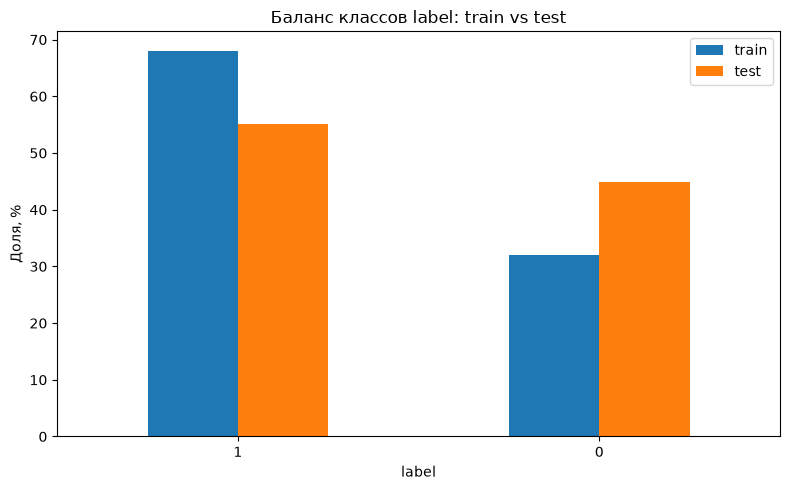

In [7]:
binary_balance = pd.DataFrame({
    "train": train["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).fillna(0) * 100

ax = binary_balance.plot(kind="bar", figsize=(8, 5))
ax.set_title("Баланс классов label: train vs test")
ax.set_xlabel("label")
ax.set_ylabel("Доля, %")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [8]:
print("TRAIN — attack_cat")
display(target_table(train, "attack_cat"))

print("TEST — attack_cat")
display(target_table(test, "attack_cat"))

attack_total = pd.DataFrame({
    "train": train["attack_cat"].value_counts(),
    "test": test["attack_cat"].value_counts(),
}).fillna(0).astype(int)

attack_total["total"] = attack_total["train"] + attack_total["test"]
attack_total["total_percent"] = 100 * attack_total["total"] / attack_total["total"].sum()

display(attack_total.sort_values("total", ascending=False))

TRAIN — attack_cat


,count,percent
attack_cat,,
Normal,56000,31.9378
Generic,40000,22.8127
Exploits,33393,19.0446
Fuzzers,18184,10.3706
DoS,12264,6.9944
Reconnaissance,10491,5.9832
Analysis,2000,1.1406
Backdoor,1746,0.9958
Shellcode,1133,0.6462


TEST — attack_cat


,count,percent
attack_cat,,
Normal,37000,44.9400
Generic,18871,22.9206
Exploits,11132,13.5209
Fuzzers,6062,7.3629
DoS,4089,4.9665
Reconnaissance,3496,4.2462
Analysis,677,0.8223
Backdoor,583,0.7081
Shellcode,378,0.4591


,train,test,total,total_percent
attack_cat,,,,
Normal,56000,37000,93000,36.0923
Generic,40000,18871,58871,22.8472
Exploits,33393,11132,44525,17.2797
Fuzzers,18184,6062,24246,9.4096
DoS,12264,4089,16353,6.3464
Reconnaissance,10491,3496,13987,5.4282
Analysis,2000,677,2677,1.0389
Backdoor,1746,583,2329,0.9039
Shellcode,1133,378,1511,0.5864


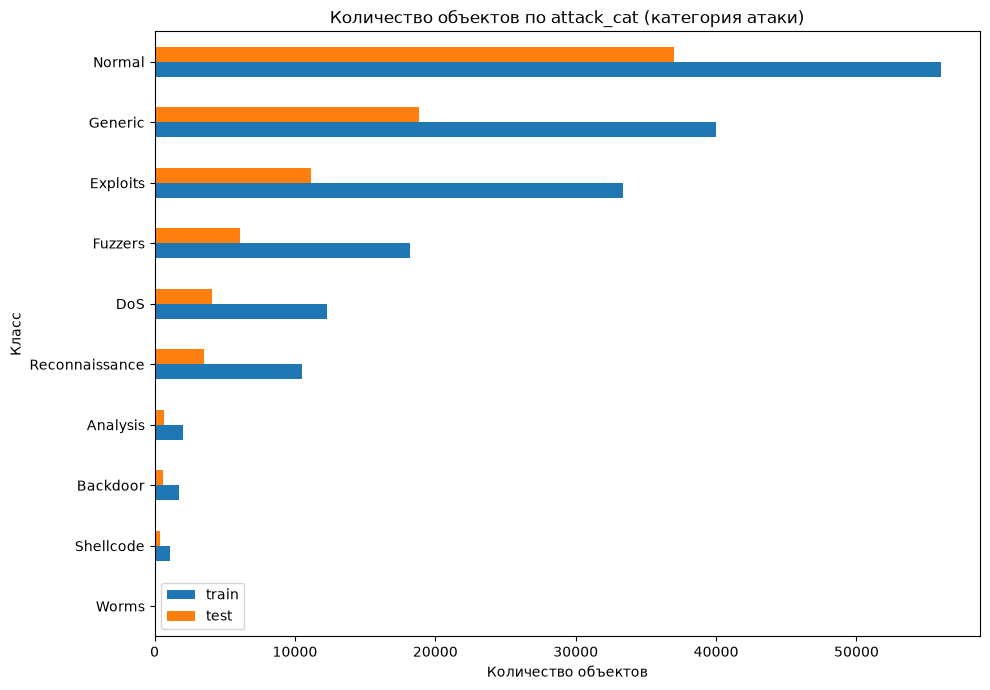

In [41]:
plot_data = attack_total.sort_values("total", ascending=True)

ax = plot_data[["train", "test"]].plot(
    kind="barh",
    figsize=(10, 7)
)
ax.set_title("Количество объектов по attack_cat (категория атаки)")
ax.set_xlabel("Количество объектов")
ax.set_ylabel("Класс")
plt.tight_layout()
plt.show()


### Вывод по целевой переменной

В train доля атак составляет 68.06% (119 341 из 175 341), в test — 55.06% (45 332 из 82 332). В объединённых данных доля атак равна 63.91%, а нормальных - 36.09%. Таким образом, аномальный класс не является редким.

При этом распределение отдельных типов атак сильно несбалансировано. Например, во всём наборе `Generic` содержит 58 871 объект, а `Worms` - только 174. 

Также виден разброс по таргету между train и test: доля атак отличается (68.06% против 55.06%).

# 4. Пропуски, пустые значения и бесконечности

In [9]:
def missing_report(df):
    report = pd.DataFrame(index=df.columns)
    report["missing"] = df.isna().sum()
    report["missing_percent"] = 100 * report["missing"] / len(df)

    blanks = []
    for col in df.columns:
        if (
            pd.api.types.is_object_dtype(df[col])
            or pd.api.types.is_string_dtype(df[col])
            or isinstance(df[col].dtype, pd.CategoricalDtype)
        ):
            blanks.append(df[col].astype("string").str.strip().eq("").sum())
        else:
            blanks.append(0)

    report["blank_strings"] = blanks
    report["blank_percent"] = 100 * report["blank_strings"] / len(df)
    return report.sort_values(
        ["missing", "blank_strings"],
        ascending=False
    )

train_missing = missing_report(train)
test_missing = missing_report(test)

print("TRAIN")
display(train_missing)

print("TEST")
display(test_missing)

print("Total NaN train:", int(train.isna().sum().sum()))
print("Total NaN test :", int(test.isna().sum().sum()))

TRAIN


,missing,missing_percent,blank_strings,blank_percent
dur,0,0.0000,0,0.0000
proto,0,0.0000,0,0.0000
service,0,0.0000,0,0.0000
state,0,0.0000,0,0.0000
spkts,0,0.0000,0,0.0000
dpkts,0,0.0000,0,0.0000
sbytes,0,0.0000,0,0.0000
dbytes,0,0.0000,0,0.0000
rate,0,0.0000,0,0.0000
sload,0,0.0000,0,0.0000


TEST


,missing,missing_percent,blank_strings,blank_percent
dur,0,0.0000,0,0.0000
proto,0,0.0000,0,0.0000
service,0,0.0000,0,0.0000
state,0,0.0000,0,0.0000
spkts,0,0.0000,0,0.0000
dpkts,0,0.0000,0,0.0000
sbytes,0,0.0000,0,0.0000
dbytes,0,0.0000,0,0.0000
rate,0,0.0000,0,0.0000
sload,0,0.0000,0,0.0000


Total NaN train: 0
Total NaN test : 0


In [10]:
def infinity_report(df):
    rows = []
    for col in df.select_dtypes(include=np.number).columns:
        values = df[col].to_numpy()
        pos_inf = np.isposinf(values).sum()
        neg_inf = np.isneginf(values).sum()
        if pos_inf or neg_inf:
            rows.append({
                "column": col,
                "+inf": int(pos_inf),
                "-inf": int(neg_inf),
            })
    return pd.DataFrame(rows, columns=["column", "+inf", "-inf"])

print("TRAIN infinite values")
display(infinity_report(train))

print("TEST infinite values")
display(infinity_report(test))

TRAIN infinite values


,column,+inf,-inf


TEST infinite values


,column,+inf,-inf


### Интерпретация пропусков

- `NaN` в train: 0;
- `NaN` в test: 0;
- пустые строковые значения: 0;
- `+inf/-inf`: 0.

Набор данных был изначально хорошо подготовлен, поэтому пропусков и бесконечных значений обнаружено не было. 

В признаке `service` есть значение `"-"`, которое, скорее всего, обозначает отсутствие распознанного или применимого сервиса. В дальнейшем это можно рассмотреть как отдельную категорию.

# 5. Проверка потенциально ошибочных значений

Для сетевых количественных показателей отрицательные значения в большинстве случаев подозрительны.  
Также отдельно проверяется бинарный target.

In [11]:
print("Unique label values:", sorted(train["label"].dropna().unique().tolist()))

unexpected_labels = set(train["label"].dropna().unique()) - {0, 1}
print("Unexpected binary labels:", unexpected_labels)

numeric_min_report = pd.DataFrame({
    "column": numeric_feature_cols,
    "min_train": [train[c].min() for c in numeric_feature_cols],
    "min_test": [test[c].min() for c in numeric_feature_cols],
    "negative_train": [(train[c] < 0).sum() for c in numeric_feature_cols],
    "negative_test": [(test[c] < 0).sum() for c in numeric_feature_cols],
})

display(
    numeric_min_report.sort_values(
        ["negative_train", "negative_test"],
        ascending=False
    )
)

Unique label values: [0, 1]
Unexpected binary labels: set()


,column,min_train,min_test,negative_train,negative_test
0,dur,0.0000,0.0000,0,0
1,spkts,1.0000,1.0000,0,0
2,dpkts,0.0000,0.0000,0,0
3,sbytes,28.0000,24.0000,0,0
4,dbytes,0.0000,0.0000,0,0
5,rate,0.0000,0.0000,0,0
6,sload,0.0000,0.0000,0,0
7,dload,0.0000,0.0000,0,0
8,sloss,0.0000,0.0000,0,0
9,dloss,0.0000,0.0000,0,0


In [39]:
# attack_cat == Normal => label == 0.

def target_consistency(df):
    attack = df["attack_cat"].astype("string").str.strip().str.lower()
    expected_label = (attack != "normal").astype(int)
    mismatch = expected_label.ne(df["label"].astype(int))
    return mismatch

for name, df in [("train", train), ("test", test)]:
    mismatch = target_consistency(df)
    print(
        f"{name}: target inconsistencies = {mismatch.sum()} "
        f"({mismatch.mean():.4%})"
    )

train: target inconsistencies = 0 (0.0000%)
test: target inconsistencies = 0 (0.0000%)


### Вывод по корректности значений

Тут, как и выше, все корректно

# 6. Выбросы 

Ниже мы будем смотреть на выбросы по интерквартильный размаху

1. считаем выбросы по IQR;
2. смотрим их долю;
3. сравниваем выбросы с `label`;
4. визуализируем наиболее асимметричные признаки;

In [13]:
def iqr_outlier_report(df, cols):
    rows = []

    for col in cols:
        s = df[col].dropna()
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        mask = (df[col] < lower) | (df[col] > upper)

        rows.append({
            "column": col,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outliers": int(mask.sum()),
            "outlier_percent": 100 * mask.mean(),
        })

    return pd.DataFrame(rows).sort_values(
        "outlier_percent",
        ascending=False
    )

iqr_report = iqr_outlier_report(train, numeric_feature_cols)
display(iqr_report)

,column,q1,q3,iqr,lower_bound,upper_bound,outliers,outlier_percent
7,dload,0.0000,"27,844.8711","27,844.8711","-41,767.3066","69,612.1777",38143,21.7536
26,ct_dst_sport_ltm,1.0000,3.0000,2.0000,-2.0000,6.0000,37337,21.2939
25,ct_src_dport_ltm,1.0000,5.0000,4.0000,-5.0000,11.0000,33423,19.0617
19,synack,0.0000,0.0233,0.0233,-0.0349,0.0582,31462,17.9433
9,dloss,0.0000,2.0000,2.0000,-3.0000,5.0000,28388,16.1902
4,dbytes,0.0000,"1,102.0000","1,102.0000","-1,653.0000","2,755.0000",28131,16.0436
1,spkts,2.0000,12.0000,10.0000,-13.0000,27.0000,24675,14.0726
22,dmean,0.0000,89.0000,89.0000,-133.5000,222.5000,23359,13.3220
3,sbytes,114.0000,"1,418.0000","1,304.0000","-1,842.0000","3,374.0000",22873,13.0449
2,dpkts,0.0000,10.0000,10.0000,-15.0000,25.0000,20830,11.8797


In [14]:
# Насколько часто IQR-выбросы являются атаками?
outlier_target_rows = []

for row in iqr_report.itertuples(index=False):
    col = row.column

    mask = (
        (train[col] < row.lower_bound)
        | (train[col] > row.upper_bound)
    )

    if mask.sum() == 0:
        attack_rate = np.nan
    else:
        attack_rate = train.loc[mask, "label"].mean()

    outlier_target_rows.append({
        "column": col,
        "n_outliers": int(mask.sum()),
        "outlier_percent": float(mask.mean() * 100),
        "attack_rate_among_outliers": attack_rate,
    })

outlier_target_report = pd.DataFrame(outlier_target_rows)
display(
    outlier_target_report.sort_values(
        "outlier_percent",
        ascending=False
    )
)

,column,n_outliers,outlier_percent,attack_rate_among_outliers
0,dload,38143,21.7536,0.1144
1,ct_dst_sport_ltm,37337,21.2939,0.9952
2,ct_src_dport_ltm,33423,19.0617,0.9731
3,synack,31462,17.9433,0.7509
4,dloss,28388,16.1902,0.3272
5,dbytes,28131,16.0436,0.2636
6,spkts,24675,14.0726,0.3089
7,dmean,23359,13.3220,0.3062
8,sbytes,22873,13.0449,0.3878
9,dpkts,20830,11.8797,0.2278


,skewness
trans_depth,167.3358
response_body_len,76.3401
sbytes,45.3034
sloss,44.7537
dloss,41.3803
spkts,40.2177
dbytes,39.7609
dpkts,36.7641
dinpkt,29.6795
djit,29.5438


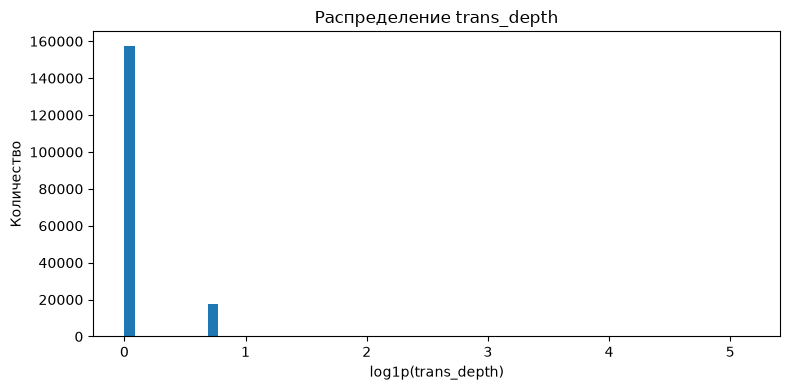

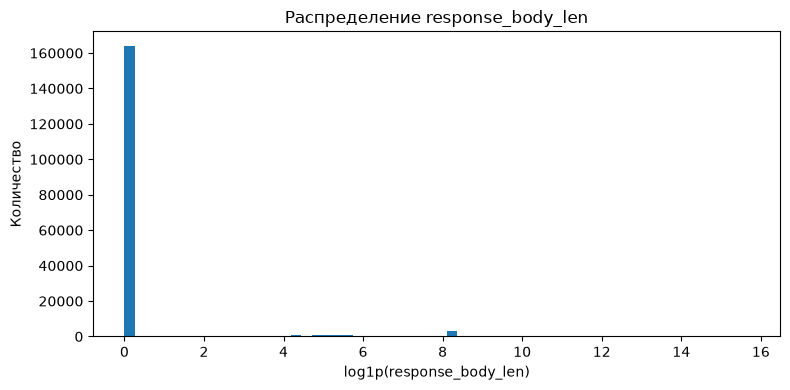

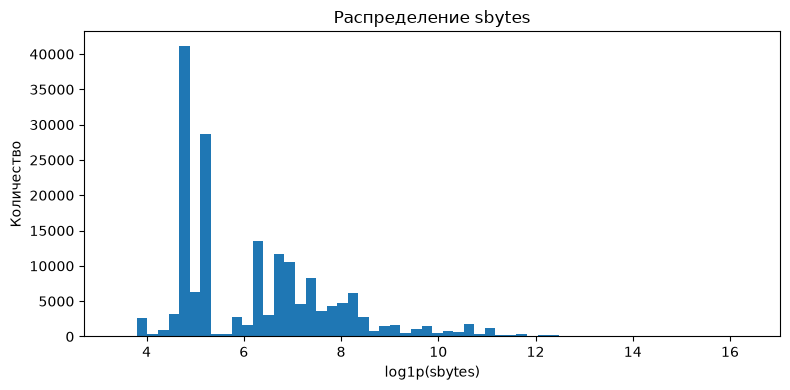

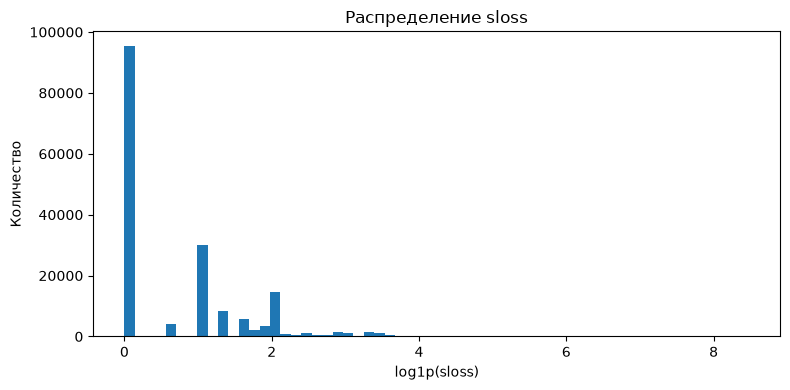

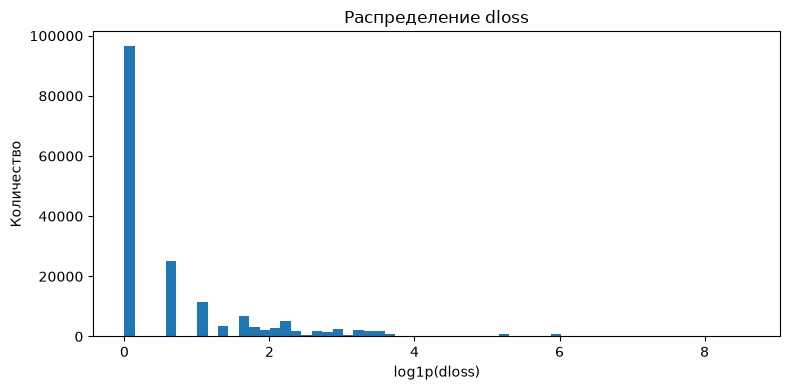

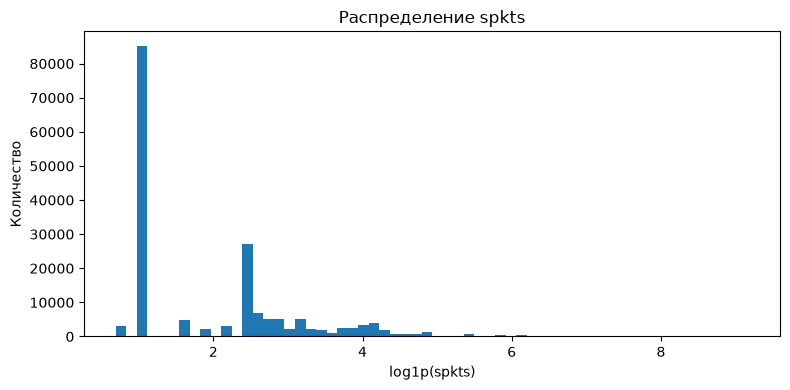

In [15]:
# Признаки с наиболее асимметричным распределением.
skewness = (
    train[numeric_feature_cols]
    .skew(numeric_only=True)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(skewness.rename("skewness").to_frame().head(12))

top_skewed = skewness.head(6).index.tolist()

for col in top_skewed:
    fig, ax = plt.subplots(figsize=(8, 4))

    values = train[col]

    if values.min() >= 0:
        ax.hist(np.log1p(values), bins=60)
        ax.set_xlabel(f"log1p({col})")
    else:
        ax.hist(values, bins=60)
        ax.set_xlabel(col)

    ax.set_title(f"Распределение {col}")
    ax.set_ylabel("Количество")
    plt.tight_layout()
    plt.show()

### Вывод по выбросам

IQR-критерий отмечает очень большую долю наблюдений как выбросы для ряда признаков: например, для `dload` около 21.75%, `ct_dst_sport_ltm` - 21.29%, `ct_src_dport_ltm` - 19.06%, `synack` - 17.94%. Это связано в том числе с сильной асимметрией распределений и большим количеством нулей.

Важно, что выбросы часто связаны с целевым классом. Среди IQR-выбросов:

- `ct_dst_sport_ltm`: 99.52% атак
- `ct_src_dport_ltm`: 97.31% атак
- `rate`: 96.53% атак
- `sload`: 88.60% атак
- `dinpkt`: 78.97% атак
- `dur`: 76.15% атак

Одновременно выбросы `dload` содержат только около 11.44% атак. Следовательно, экстремальность сама по себе не означает ни ошибку, ни атаку - её смысл зависит от конкретного признака.

Распределения сильно скошены: например, skewness достигает 167.34 для `trans_depth`, 76.34 для `response_body_len`, более 45 для `sbytes`.

# 7. Одномерный анализ признаков

## 7.1. Числовые признаки

Для каждого числового признака смотрим:

- медиану
- среднее
- стандартное отклонение
- квантили
- долю нулей
- коэффициент асимметрии

In [16]:
numeric_univariate = pd.DataFrame({
    "mean": train[numeric_feature_cols].mean(),
    "median": train[numeric_feature_cols].median(),
    "std": train[numeric_feature_cols].std(),
    "min": train[numeric_feature_cols].min(),
    "q01": train[numeric_feature_cols].quantile(0.01),
    "q25": train[numeric_feature_cols].quantile(0.25),
    "q75": train[numeric_feature_cols].quantile(0.75),
    "q99": train[numeric_feature_cols].quantile(0.99),
    "max": train[numeric_feature_cols].max(),
    "zero_percent": 100 * (train[numeric_feature_cols] == 0).mean(),
    "skewness": train[numeric_feature_cols].skew(),
})

display(
    numeric_univariate.sort_values(
        "skewness",
        key=lambda s: s.abs(),
        ascending=False
    )
)

,mean,median,std,min,q01,q25,q75,q99,max,zero_percent,skewness
trans_depth,0.1060,0.0000,0.7769,0.0000,0.0000,0.0000,0.0000,1.0000,172.0000,89.8255,167.3358
response_body_len,"2,144.2917",0.0000,"54,207.9673",0.0000,0.0000,0.0000,0.0000,"3,924.0000","6,558,056.0000",93.5588,76.3401
sbytes,"8,844.8438",430.0000,"174,765.6443",28.0000,46.0000,114.0000,"1,418.0000","74,125.4000","12,965,233.0000",0.0000,45.3034
sloss,4.9530,0.0000,66.0051,0.0000,0.0000,0.0000,3.0000,38.0000,"4,803.0000",54.4356,44.7537
dloss,6.9480,0.0000,52.7330,0.0000,0.0000,0.0000,2.0000,178.6000,"5,484.0000",55.1137,41.3803
spkts,20.2987,2.0000,136.8876,1.0000,1.0000,2.0000,12.0000,234.0000,"9,616.0000",0.0000,40.2177
dbytes,"14,928.9186",164.0000,"143,654.2177",0.0000,0.0000,0.0000,"1,102.0000","474,367.8000","14,655,550.0000",48.0675,39.7609
dpkts,18.9696,2.0000,110.2583,0.0000,0.0000,0.0000,10.0000,400.0000,"10,974.0000",48.0675,36.7641
dinpkt,88.2163,0.0060,987.0932,0.0000,0.0000,0.0000,51.0530,441.6530,"56,716.8242",48.0738,29.6795
djit,604.3538,0.0000,"4,061.0432",0.0000,0.0000,0.0000,114.9906,"9,466.0188","289,388.2812",53.4633,29.5438


## 7.2. Категориальные признаки

In [17]:
categorical_summary = pd.DataFrame({
    "column": categorical_feature_cols,
    "n_unique_train": [
        train[c].nunique(dropna=False)
        for c in categorical_feature_cols
    ],
    "n_unique_test": [
        test[c].nunique(dropna=False)
        for c in categorical_feature_cols
    ],
})

display(categorical_summary)

for col in categorical_feature_cols:
    print(f"\n{col}")

    temp = pd.DataFrame({
        "count": train[col].value_counts(dropna=False),
        "percent": 100 * train[col].value_counts(
            normalize=True,
            dropna=False
        ),
    })

    display(temp.head(25))

,column,n_unique_train,n_unique_test
0,proto,133,131
1,service,13,13
2,state,9,7



proto


,count,percent
proto,,
tcp,79946,45.5946
udp,63283,36.0914
unas,12084,6.8917
arp,2859,1.6305
ospf,2595,1.4800
sctp,1150,0.6559
any,300,0.1711
gre,225,0.1283
ipv6,201,0.1146



service


,count,percent
service,,
-,94168,53.7056
dns,47294,26.9726
http,18724,10.6786
smtp,5058,2.8847
ftp-data,3995,2.2784
ftp,3428,1.9550
ssh,1302,0.7426
pop3,1105,0.6302
dhcp,94,0.0536



state


,count,percent
state,,
INT,82275,46.9229
FIN,77825,44.3849
CON,13152,7.5008
REQ,1991,1.1355
RST,83,0.0473
ECO,12,0.0068
PAR,1,0.0006
URN,1,0.0006
no,1,0.0006


### Вывод по одномерным распределениям

Категориальные признаки имеют заметно неравномерные распределения. В train:

- `proto=tcp`: 45.59%, `udp`: 36.09%;
- `service="-"`: 53.71%, `dns`: 26.97%, `http`: 10.68%;
- `state=INT`: 46.92%, `FIN`: 44.38%, `CON`: 7.50%.

Одновременно существует длинный хвост редких значений `proto`.

Числовые распределения также часто имеют большую концентрацию около нуля и длинные правые хвосты. В дальнейшем полезнее опираться также на медианы, квантили и ранговые статистики.

# 8. Связь признаков с целевой переменной

Используем:

- Pearson/Spearman для числовых признаков;
- attack rate и Cramer's V для категориальных;
- One-Hot Encoding -  как дополнительный анализ категорий.

## 8.1. Числовые признаки и таргет

In [18]:
pearson_with_label = (
    train[numeric_feature_cols + ["label"]]
    .corr(method="pearson")["label"]
    .drop("label")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

spearman_with_label = (
    train[numeric_feature_cols + ["label"]]
    .corr(method="spearman")["label"]
    .drop("label")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

numeric_target_assoc = pd.DataFrame({
    "pearson": pearson_with_label,
    "spearman": spearman_with_label,
})

numeric_target_assoc["abs_spearman"] = (
    numeric_target_assoc["spearman"].abs()
)

display(
    numeric_target_assoc.sort_values(
        "abs_spearman",
        ascending=False
    )
)

,pearson,spearman,abs_spearman
dload,-0.3937,-0.6258,0.6258
dmean,-0.3418,-0.5463,0.5463
dbytes,-0.0769,-0.4913,0.4913
dpkts,-0.1186,-0.4850,0.4850
ct_dst_sport_ltm,0.3572,0.4299,0.4299
dloss,-0.0947,-0.3884,0.3884
sloss,-0.0006,-0.3805,0.3805
spkts,-0.0522,-0.3541,0.3541
sbytes,0.0186,-0.3361,0.3361
swin,-0.3336,-0.3337,0.3337


### Вывод по числовым признакам и таргету

Наиболее сильные монотонные связи по Spearman наблюдаются у:

- `dload`: -0.626
- `dmean`: -0.546
- `dbytes`: -0.491
- `dpkts`: -0.485
- `ct_dst_sport_ltm`: 0.430

Для нескольких признаков Pearson и Spearman существенно различаются. Например:

- `sbytes`: Pearson 0.019, Spearman -0.336
- `dur`: Pearson 0.036, Spearman -0.230
- `dinpkt`: Pearson -0.023**, Spearman -0.275

Это согласуется с обнаруженной сильной асимметрией распределений: линейная Pearson-корреляция не всегда отражает реальную монотонную связь. Спирмена мы используем как дополнение к Пирсону.

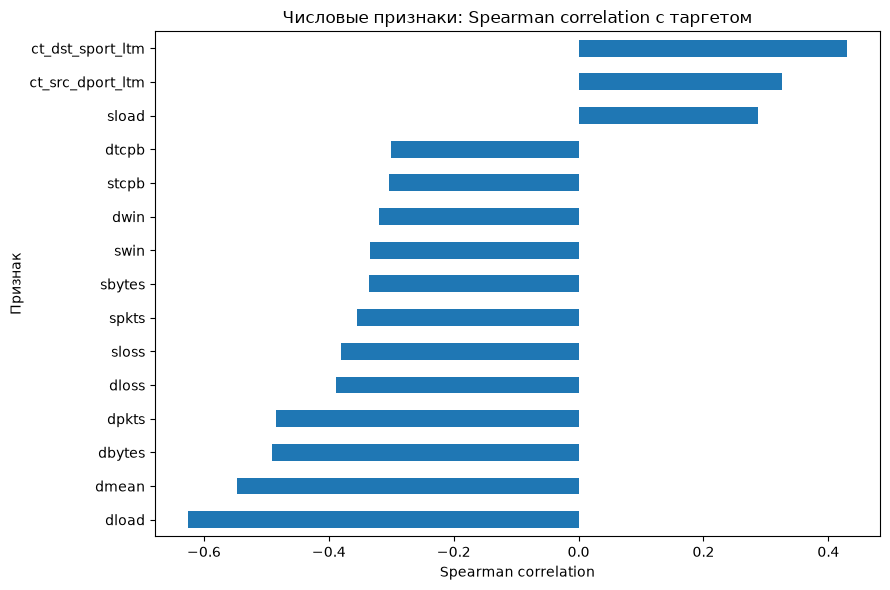

In [42]:
top_corr = (
    numeric_target_assoc
    .sort_values("abs_spearman", ascending=False)
    .head(15)
    .sort_values("spearman")
)

ax = top_corr["spearman"].plot(
    kind="barh",
    figsize=(9, 6)
)
ax.set_title("Числовые признаки: Spearman correlation с таргетом")
ax.set_xlabel("Spearman correlation")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

## 8.2. Категориальные признаки и таргет

### Cramer's V

Cramer's V измеряет силу связи между двумя категориальными переменными.

Для `label` значения:

- ближе к 0 — слабая связь;
- ближе к 1 — сильная связь.

In [20]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    if n <= 1:
        return np.nan

    phi2 = chi2 / n
    r, k = table.shape

    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)

    if denom <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denom)

cat_assoc = []

for col in categorical_feature_cols:
    cat_assoc.append({
        "column": col,
        "n_unique": train[col].nunique(dropna=False),
        "cramers_v_with_label": cramers_v(
            train[col],
            train["label"]
        ),
    })

cat_assoc = (
    pd.DataFrame(cat_assoc)
    .sort_values("cramers_v_with_label", ascending=False)
)

display(cat_assoc)

,column,n_unique,cramers_v_with_label
2,state,9,0.5588
0,proto,133,0.4342
1,service,13,0.2720


In [43]:
# Attack rate по наиболее частым значениям каждой категории.
for col in categorical_feature_cols:
    print(f"\n{col}: attack rate")

    stats = (
        train.groupby(col, observed=True)["label"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "attack_rate"})
        .sort_values("count", ascending=False)
    )

    stats["attack_rate_percent"] = 100 * stats["attack_rate"]

    display(stats.head(30))


proto: attack rate


,count,attack_rate,attack_rate_percent
proto,,,
tcp,79946,0.5107,51.0657
udp,63283,0.7800,78.0004
unas,12084,1.0000,100.0000
arp,2859,0.0000,0.0000
ospf,2595,0.9753,97.5337
sctp,1150,1.0000,100.0000
any,300,1.0000,100.0000
gre,225,1.0000,100.0000
swipe,201,1.0000,100.0000



service: attack rate


,count,attack_rate,attack_rate_percent
service,,,
-,94168,0.6123,61.2267
dns,47294,0.8416,84.1566
http,18724,0.7144,71.4377
smtp,5058,0.6878,68.7821
ftp-data,3995,0.3612,36.1202
ftp,3428,0.6447,64.4691
ssh,1302,0.0084,0.8449
pop3,1105,0.9964,99.6380
dhcp,94,1.0000,100.0000



state: attack rate


,count,attack_rate,attack_rate_percent
state,,,
INT,82275,0.9305,93.0538
FIN,77825,0.5223,52.2326
CON,13152,0.0801,8.0064
REQ,1991,0.5354,53.5409
RST,83,0.1446,14.4578
ECO,12,0.0000,0.0000
PAR,1,0.0000,0.0000
URN,1,0.0000,0.0000
no,1,0.0000,0.0000


## 8.3. Дополнительный One-Hot анализ категорий

Здесь для каждой категории создаётся бинарный индикатор и считается его корреляция с `label`.

In [22]:
categorical_dummies = pd.get_dummies(
    train[categorical_feature_cols],
    prefix=categorical_feature_cols,
    drop_first=False,
    dtype="int8",
)

dummy_corr = (
    categorical_dummies
    .assign(label=train["label"].to_numpy())
    .corr(numeric_only=True)["label"]
    .drop("label")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(
    dummy_corr.rename("correlation_with_label")
    .to_frame()
    .head(30)
)

,correlation_with_label
state_INT,0.5040
state_CON,-0.3668
proto_tcp,-0.3337
state_FIN,-0.3033
service_dns,0.2098
proto_arp,-0.1879
proto_unas,0.1864
proto_udp,0.1602
service_-,-0.1579
service_ssh,-0.1247


### Вывод по категориальным признакам

Все три категориальных признака связаны с `label`, но сила связи различается:

- `state`: 0.559
- `proto`: 0.434
- `service`: 0.272

Особенно заметны различия attack rate:

- `state=INT`: 93.05% атак
- `state=CON`: 8.01%
- `service=dns`: 84.16%
- `service=ssh`: 0.84%
- `service=pop3`: 99.64%

Таким образом, категориальные признаки потенциально очень полезны для модели. При этом многие редкие значения `proto` имеют 100%-й attack rate всего на десятках или сотнях объектов.

# 9. Попарные корреляции числовых признаков

Полная heatmap из десятков признаков плохо читается, поэтому:

1. рассчитываем полную матрицу;
2. ищем наиболее сильные пары;
3. визуализируем компактный набор наиболее информативных признаков.

In [23]:
corr_numeric = train[numeric_feature_cols].corr(method="spearman")

pairs = []

for i, col1 in enumerate(corr_numeric.columns):
    for j in range(i + 1, len(corr_numeric.columns)):
        col2 = corr_numeric.columns[j]
        corr_value = corr_numeric.iloc[i, j]

        pairs.append({
            "feature_1": col1,
            "feature_2": col2,
            "spearman": corr_value,
            "abs_spearman": abs(corr_value),
        })

strong_pairs = (
    pd.DataFrame(pairs)
    .sort_values("abs_spearman", ascending=False)
)

display(strong_pairs.head(30))

,feature_1,feature_2,spearman,abs_spearman
459,is_ftp_login,ct_ftp_cmd,1.0000,1.0000
442,trans_depth,ct_flw_http_mthd,0.9996,0.9996
387,tcprtt,synack,0.9968,0.9968
388,tcprtt,ackdat,0.9937,0.9937
331,swin,dwin,0.9902,0.9902
60,dpkts,dbytes,0.9899,0.9899
399,synack,ackdat,0.9844,0.9844
131,dbytes,dmean,0.9631,0.9631
203,dload,dmean,0.9629,0.9629
140,rate,sload,0.9604,0.9604


### Вывод по попарным корреляциям

В данных присутствует несколько практически дублирующих или очень тесно связанных числовых признаков:

- `is_ftp_login` и `ct_ftp_cmd`: 1.000
- `trans_depth` и `ct_flw_http_mthd`: 0.9996
- `tcprtt` и `synack`: 0.9968
- `tcprtt` и `ackdat`: 0.9937
- `swin` и `dwin`: 0.9902
- `dpkts` и `dbytes`: 0.9899
- `dload` и `dmean`: 0.9629
- `rate` и `sload`: 0.9604

Это указывает на выраженную мультиколлинеарность и частичную избыточность признакового пространства. Для линейных моделей потребуется регуляризация и, возможно, дополнительный feature selection. Для деревьев высокая корреляция не является критической технической проблемой, но может распределять вклад между взаимозаменяемыми признаками и усложнять интерпретацию.

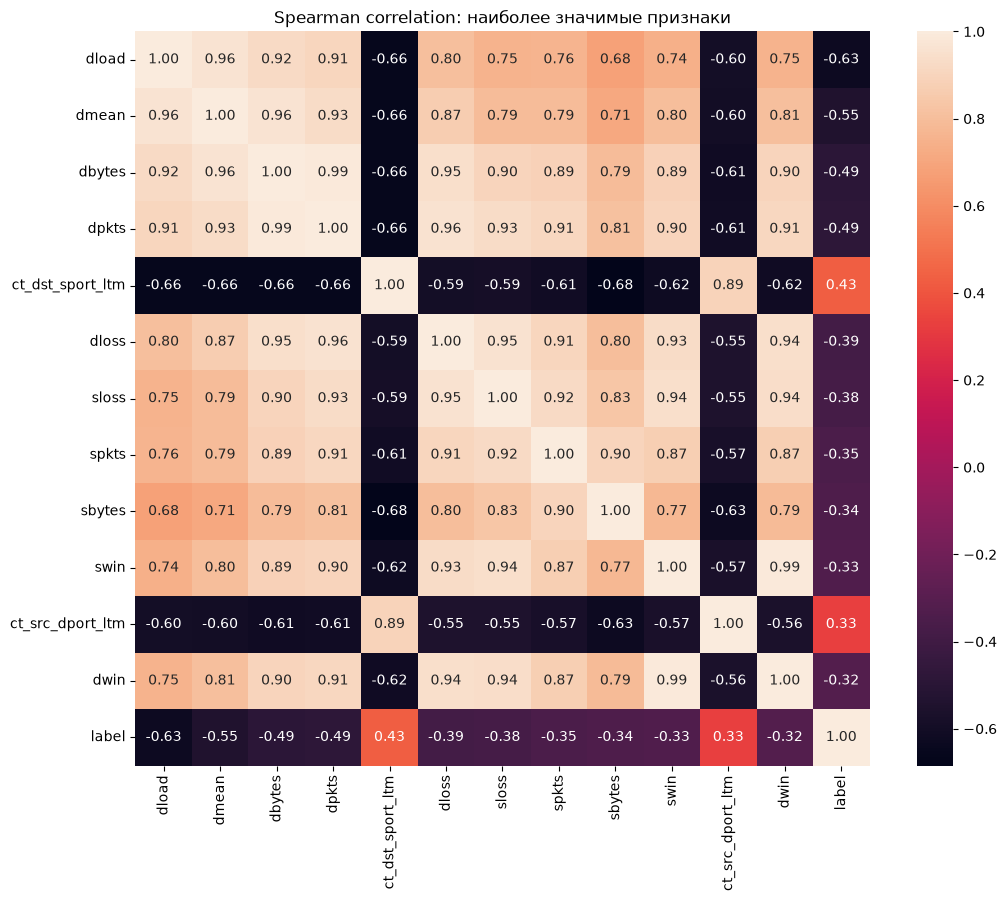

In [44]:
top_numeric_for_heatmap = (
    numeric_target_assoc
    .sort_values("abs_spearman", ascending=False)
    .head(12)
    .index
    .tolist()
)

heatmap_cols = top_numeric_for_heatmap + ["label"]

heatmap_corr = train[heatmap_cols].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(
    heatmap_corr,
    annot=True,
    fmt=".2f",
    square=True,
)
plt.title("Spearman correlation: наиболее значимые признаки")
plt.tight_layout()
plt.show()

# 10. Pairplot

Поэтому выбираем 5 наиболее связанных с `label` числовых признаков и делаем стратифицированную подвыборку.
(pairplot на всех признаках будет не оч информативным)

Pairplot features: ['dload', 'dmean', 'dbytes', 'dpkts', 'ct_dst_sport_ltm']
Sample size: 5000


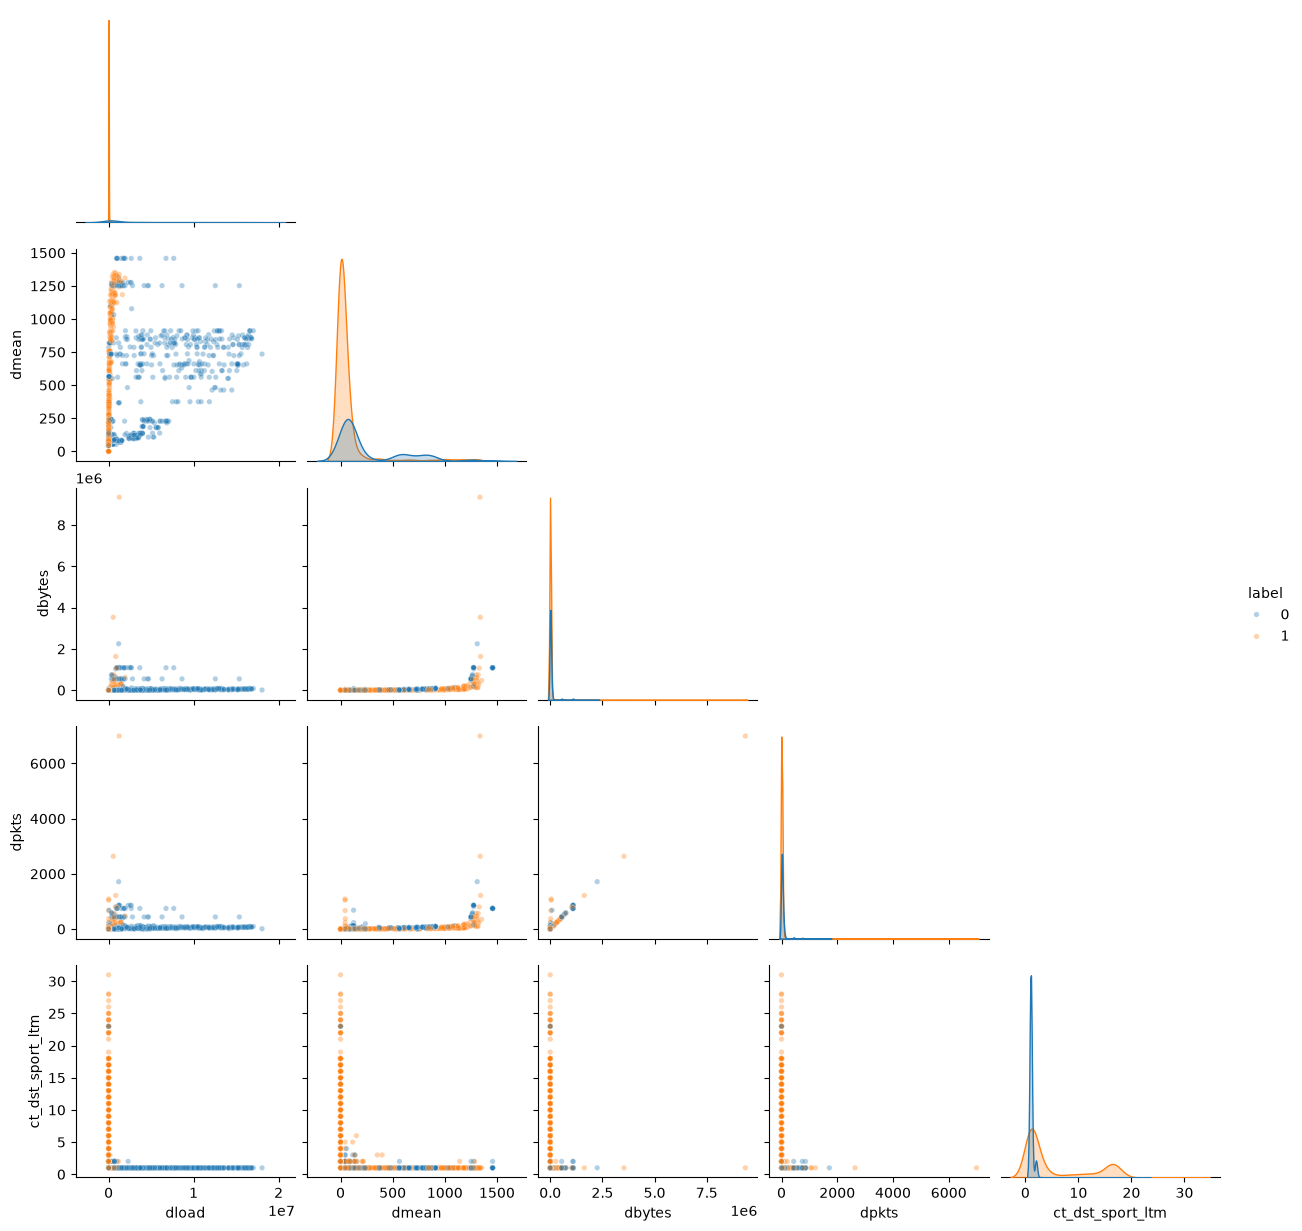

In [25]:
def stratified_sample_binary(df, target="label", n=5000, random_state=42):
    parts = []

    shares = df[target].value_counts(normalize=True)

    for cls, share in shares.items():
        n_cls = max(1, round(n * share))
        subset = df[df[target] == cls]

        parts.append(
            subset.sample(
                n=min(n_cls, len(subset)),
                random_state=random_state,
            )
        )

    return (
        pd.concat(parts)
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

pair_features = (
    numeric_target_assoc
    .sort_values("abs_spearman", ascending=False)
    .head(5)
    .index
    .tolist()
)

pair_sample = stratified_sample_binary(
    train[pair_features + ["label"]],
    n=5000,
    random_state=42,
)

print("Pairplot features:", pair_features)
print("Sample size:", len(pair_sample))

sns.pairplot(
    pair_sample,
    vars=pair_features,
    hue="label",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 15},
)
plt.show()

# 11. Дубликаты

Теперь переходим к особенностям качества данных, которые наиболее заметно влияют на этот датасет.

Различаем:

1. полные дубли строк - совпадают и признаки, и targets
2. одинаковые feature vectors - совпадают только входные признаки `X`
3. одинаковый `X`, но разные targets - конфликт
4. одинаковый `X` между train и test - смешивание

In [45]:
print("Exact full-row duplicates")
print("Train:", train.duplicated().sum())
print("Test :", test.duplicated().sum())

print("\nDuplicates by model features X")
print(
    "Train:",
    train.duplicated(subset=feature_cols).sum()
)
print(
    "Test :",
    test.duplicated(subset=feature_cols).sum()
)

Exact full-row duplicates
Train: 78519
Test : 32361

Duplicates by model features X
Train: 83243
Test : 34101


In [27]:
def add_feature_hash(df):
    result = df.copy()
    result["_feature_hash"] = pd.util.hash_pandas_object(
        result[feature_cols],
        index=False
    ).to_numpy()
    return result

train_h = add_feature_hash(train)
test_h = add_feature_hash(test)

duplicate_summary = pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(train_h), len(test_h)],
    "unique_X": [
        train_h["_feature_hash"].nunique(),
        test_h["_feature_hash"].nunique(),
    ],
})

duplicate_summary["duplicate_rows_by_X"] = (
    duplicate_summary["rows"] - duplicate_summary["unique_X"]
)

duplicate_summary["duplicate_percent_by_X"] = (
    100
    * duplicate_summary["duplicate_rows_by_X"]
    / duplicate_summary["rows"]
)

display(duplicate_summary)

,split,rows,unique_X,duplicate_rows_by_X,duplicate_percent_by_X
0,train,175341,92098,83243,47.4749
1,test,82332,48231,34101,41.4189


## 11.1. Одинаковые `X`, но разные targets




In [28]:
def conflict_summary(df_h, target):
    grouped = (
        df_h.groupby("_feature_hash", observed=True)[target]
        .agg(n_rows="size", n_unique_targets="nunique")
    )

    conflicts = grouped[
        grouped["n_unique_targets"] > 1
    ]

    rows_affected = df_h["_feature_hash"].isin(
        conflicts.index
    ).sum()

    return {
        "target": target,
        "unique_X": grouped.shape[0],
        "conflicting_X": conflicts.shape[0],
        "rows_affected": int(rows_affected),
        "rows_affected_percent": 100 * rows_affected / len(df_h),
    }

conflicts_table = pd.DataFrame([
    {"split": "train", **conflict_summary(train_h, "label")},
    {"split": "train", **conflict_summary(train_h, "attack_cat")},
    {"split": "test", **conflict_summary(test_h, "label")},
    {"split": "test", **conflict_summary(test_h, "attack_cat")},
])

display(conflicts_table)

,split,target,unique_X,conflicting_X,rows_affected,rows_affected_percent
0,train,label,92098,259,5585,3.1852
1,train,attack_cat,92098,1397,35616,20.3124
2,test,label,48231,122,1914,2.3247
3,test,attack_cat,48231,582,10759,13.0678


## 11.2. Пересечение train/test по `X`

Создаём две части исходного test:

- `test_seen` - такой feature vector уже был в train
- `test_unseen` - такой feature vector в train не встречался

In [46]:
train_hashes = set(train_h["_feature_hash"].unique())

seen_mask = test_h["_feature_hash"].isin(train_hashes)

test_seen = test.loc[seen_mask].copy()
test_unseen = test.loc[~seen_mask].copy()

seen_unseen = pd.DataFrame({
    "subset": ["official_test", "test_seen", "test_unseen"],
    "rows": [len(test), len(test_seen), len(test_unseen)],
    "share_of_official_test": [
        1.0,
        len(test_seen) / len(test),
        len(test_unseen) / len(test),
    ],
    "attack_share": [
        test["label"].mean(),
        test_seen["label"].mean(),
        test_unseen["label"].mean(),
    ],
})

display(seen_unseen)

,subset,rows,share_of_official_test,attack_share
0,official_test,82332,1.0000,0.5506
1,test_seen,20851,0.2533,0.7890
2,test_unseen,61481,0.7467,0.4697


`official_test` — исходный test из датасета (82 332 строки). Его мы не создавали и не изменяли.

Для дополнительной диагностики мы сами разделили его на:

- `test_seen` - 20 851 строку (25.33%), чей feature vector уже встречался в train
- `test_unseen` - 61 481 строку (74.67%), чей feature vector в train не встречался

Эти две части полностью образуют исходный `official_test`.

В `test_seen` доля атак равна 78.90%, а в `test_unseen` - 46.97%. Из-за такого разного баланса классов, не стоит опираться только на accuracy

# 12. Создание версии данных без дубликатов

В данных есть feature vectors с конфликтующим `label`.

1. находим feature vectors, у которых встречается более одного `label`
2. откладываем эти неоднозначные группы отдельно
3. среди оставшихся однозначных `X` сохраняем ровно одну строку

Так получаем `dedup_binary`.

То есть мы удаляем feature vectors с конфликтующим label, а среди оставшихся однозначных feature vectors оставляем по одному экземпляру.

В последущем, можно будет более органично разделить датасет по `attack_cat`, если доберемся до multi-class классификации

In [47]:
def make_binary_safe_dedup(df, feature_cols):
    temp = df.copy()

    temp["_feature_hash"] = pd.util.hash_pandas_object(
        temp[feature_cols],
        index=False
    ).to_numpy()

    label_nunique = (
        temp.groupby("_feature_hash", observed=True)["label"]
        .nunique()
    )

    conflict_hashes = set(
        label_nunique[label_nunique > 1].index
    )

    conflicts = temp[
        temp["_feature_hash"].isin(conflict_hashes)
    ].copy()

    clean = temp[
        ~temp["_feature_hash"].isin(conflict_hashes)
    ].copy()

    dedup = (
        clean
        .drop_duplicates(subset="_feature_hash", keep="first")
        .drop(columns="_feature_hash")
        .reset_index(drop=True)
    )

    conflicts = (
        conflicts
        .drop(columns="_feature_hash")
        .reset_index(drop=True)
    )

    return dedup, conflicts


train_dedup, train_label_conflicts = make_binary_safe_dedup(
    train,
    feature_cols
)

test_dedup, test_label_conflicts = make_binary_safe_dedup(
    test,
    feature_cols
)

dedup_summary = pd.DataFrame({
    "split": ["train", "test"],
    "original_rows": [len(train), len(test)],
    "deduplicated_rows": [len(train_dedup), len(test_dedup)],
    "conflict_rows_removed": [
        len(train_label_conflicts),
        len(test_label_conflicts),
    ],
})

dedup_summary["rows_removed_total"] = (
    dedup_summary["original_rows"]
    - dedup_summary["deduplicated_rows"]
)

dedup_summary["rows_removed_percent"] = (
    100
    * dedup_summary["rows_removed_total"]
    / dedup_summary["original_rows"]
)

display(dedup_summary)

,split,original_rows,deduplicated_rows,conflict_rows_removed,rows_removed_total,rows_removed_percent
0,train,175341,91839,5585,83502,47.6226
1,test,82332,48109,1914,34223,41.5671


# 13. Original vs deduplicated

Теперь рассматриваем данные в двух версиях:

- **Original** — исходный benchmark;
- **Deduplicated** — binary-safe версия: конфликтующие `X` исключены, остальные `X` представлены один раз.

## 13.1. Изменение баланса классов

In [48]:
def class_balance_compare(original, dedup, target):
    a = original[target].value_counts(normalize=True, dropna=False) * 100
    b = dedup[target].value_counts(normalize=True, dropna=False) * 100

    out = pd.DataFrame({
        "original_percent": a,
        "deduplicated_percent": b,
    }).fillna(0)

    out["change_pp"] = (
        out["deduplicated_percent"]
        - out["original_percent"]
    )

    return out

print("TRAIN — label")
display(
    class_balance_compare(
        train,
        train_dedup,
        "label"
    )
)

print("TEST — label")
display(
    class_balance_compare(
        test,
        test_dedup,
        "label"
    )
)

print("TRAIN — attack_cat")
display(
    class_balance_compare(
        train,
        train_dedup,
        "attack_cat"
    ).sort_values(
        "original_percent",
        ascending=False
    )
)

TRAIN — label


,original_percent,deduplicated_percent,change_pp
label,,,
0,31.9378,52.9568,21.0190
1,68.0622,47.0432,-21.0190


TEST — label


,original_percent,deduplicated_percent,change_pp
label,,,
0,44.9400,65.4514,20.5114
1,55.0600,34.5486,-20.5114


TRAIN — attack_cat


,original_percent,deduplicated_percent,change_pp
attack_cat,,,
Normal,31.9378,52.9568,21.0190
Generic,22.8127,1.7291,-21.0836
Exploits,19.0446,20.2169,1.1723
Fuzzers,10.3706,14.2358,3.8651
DoS,6.9944,3.0270,-3.9673
Reconnaissance,5.9832,5.6958,-0.2874
Analysis,1.1406,0.5085,-0.6321
Backdoor,0.9958,0.5052,-0.4905
Shellcode,0.6462,0.9974,0.3512


## 13.2. Изменение основных статистик числовых признаков

Если mean/median сильно меняются после deduplication, значит дубликаты существенно влияют на распределение данных.

In [49]:
original_stats = train[numeric_feature_cols].agg(
    ["mean", "median", "std"]
).T

dedup_stats = train_dedup[numeric_feature_cols].agg(
    ["mean", "median", "std"]
).T

stats_compare = original_stats.add_prefix("original_").join(
    dedup_stats.add_prefix("dedup_")
)

stats_compare["mean_relative_change"] = (
    (stats_compare["dedup_mean"] - stats_compare["original_mean"])
    / stats_compare["original_mean"].replace(0, np.nan)
)

stats_compare["median_relative_change"] = (
    (stats_compare["dedup_median"] - stats_compare["original_median"])
    / stats_compare["original_median"].replace(0, np.nan)
)

display(
    stats_compare.sort_values(
        "mean_relative_change",
        key=lambda s: s.abs(),
        ascending=False
    )
)

,original_mean,original_median,original_std,dedup_mean,dedup_median,dedup_std,mean_relative_change,median_relative_change
dload,"671,205.6250","1,447.0227","2,421,312.2500","1,266,675.2500","12,859.4502","3,230,363.7500",0.8872,7.8868
sloss,4.9530,0.0000,66.0051,9.2474,2.0000,90.9512,0.8670,NaN
rate,"95,406.1797","3,225.8066","165,400.9688","13,153.4170",58.1221,"65,564.3672",-0.8621,-0.9820
dbytes,"14,928.9186",164.0000,"143,654.2177","27,572.5366",774.0000,"189,105.2629",0.8469,3.7195
dpkts,18.9696,2.0000,110.2583,34.9949,10.0000,144.3361,0.8448,4.0000
dloss,6.9480,0.0000,52.7330,12.8085,2.0000,69.1554,0.8435,NaN
dmean,124.1734,44.0000,258.3171,228.2260,81.0000,318.2466,0.8380,0.8409
trans_depth,0.1060,0.0000,0.7769,0.1934,0.0000,1.0542,0.8246,NaN
stcpb,"969,250,421.9105",0.0000,"1,355,264,249.2630","1,766,324,768.5954","1,684,069,583.0000","1,393,645,480.2335",0.8224,NaN
response_body_len,"2,144.2917",0.0000,"54,207.9673","3,905.0050",0.0000,"70,529.0114",0.8211,NaN


## 13.3. Корреляции с `label`: original vs deduplicated

In [33]:
orig_spearman = (
    train[numeric_feature_cols + ["label"]]
    .corr(method="spearman")["label"]
    .drop("label")
)

dedup_spearman = (
    train_dedup[numeric_feature_cols + ["label"]]
    .corr(method="spearman")["label"]
    .drop("label")
)

corr_compare = pd.DataFrame({
    "original_spearman": orig_spearman,
    "dedup_spearman": dedup_spearman,
})

corr_compare["change"] = (
    corr_compare["dedup_spearman"]
    - corr_compare["original_spearman"]
)

corr_compare["abs_change"] = corr_compare["change"].abs()

display(
    corr_compare.sort_values(
        "abs_change",
        ascending=False
    )
)

,original_spearman,dedup_spearman,change,abs_change
dinpkt,-0.2749,0.4414,0.7162,0.7162
rate,0.2867,-0.4007,-0.6873,0.6873
ackdat,-0.1554,0.5114,0.6668,0.6668
sload,0.2876,-0.3691,-0.6567,0.6567
tcprtt,-0.1627,0.4917,0.6543,0.6543
synack,-0.1650,0.4853,0.6504,0.6504
sinpkt,-0.2374,0.3967,0.6341,0.6341
dur,-0.2302,0.3700,0.6002,0.6002
sjit,-0.2009,0.3909,0.5918,0.5918
djit,-0.2397,0.3162,0.5559,0.5559


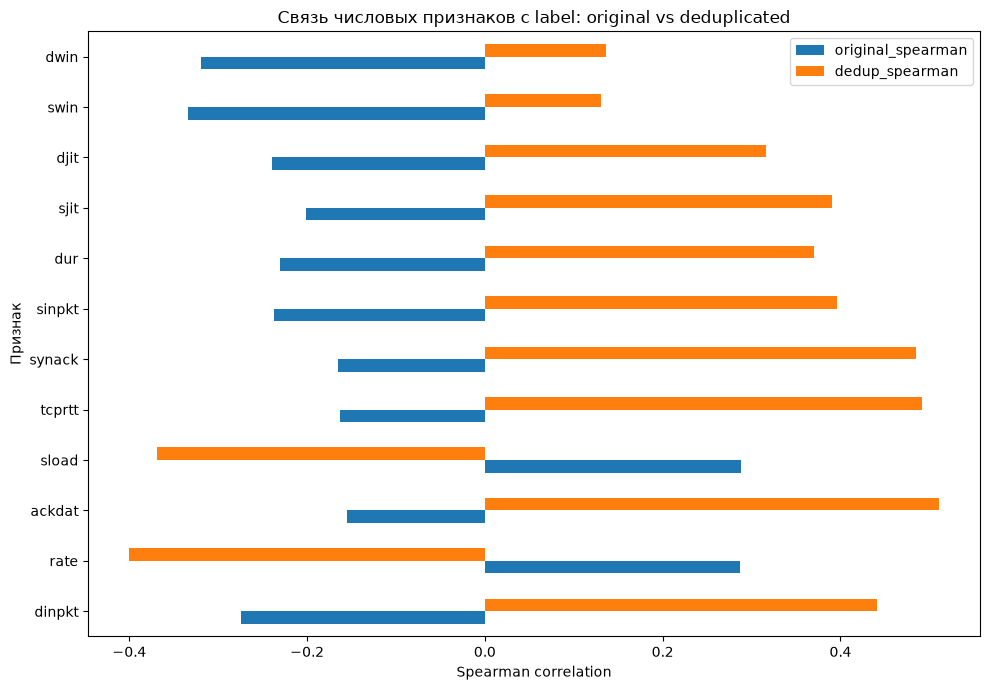

In [34]:
top_change_features = (
    corr_compare
    .sort_values("abs_change", ascending=False)
    .head(12)
    .index
)

plot_corr = corr_compare.loc[
    top_change_features,
    ["original_spearman", "dedup_spearman"]
]

ax = plot_corr.plot(
    kind="barh",
    figsize=(10, 7)
)
ax.set_title(
    "Связь числовых признаков с label: original vs deduplicated"
)
ax.set_xlabel("Spearman correlation")
ax.set_ylabel("Признак")
plt.tight_layout()
plt.show()

## 13.4. Распределения selected features: original vs deduplicated

Для визуального сравнения берём признаки, у которых после deduplication сильнее всего изменилась связь с target.

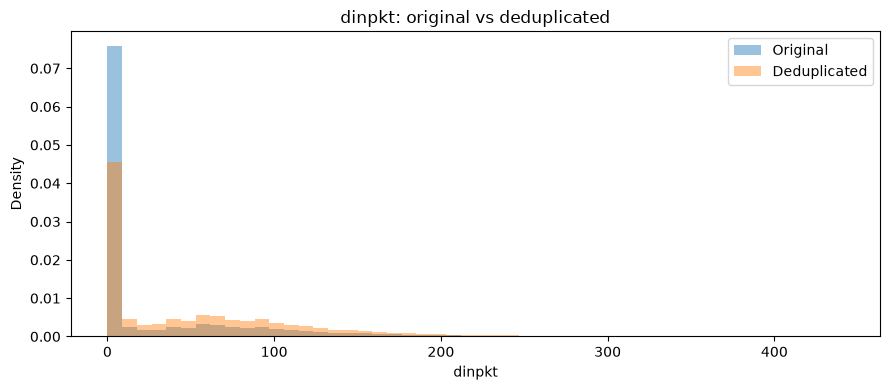

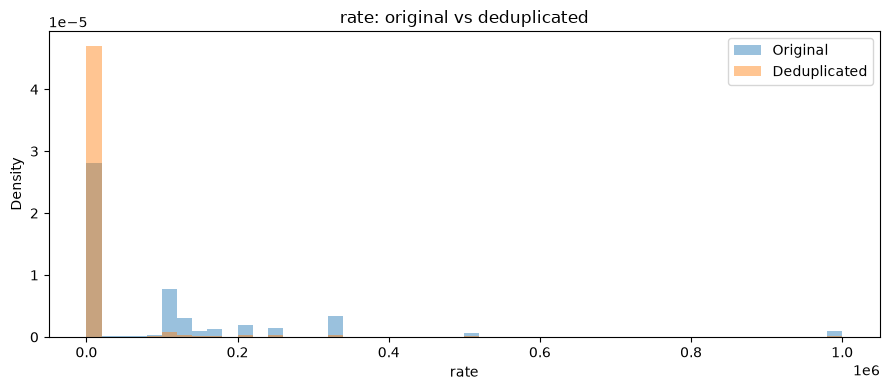

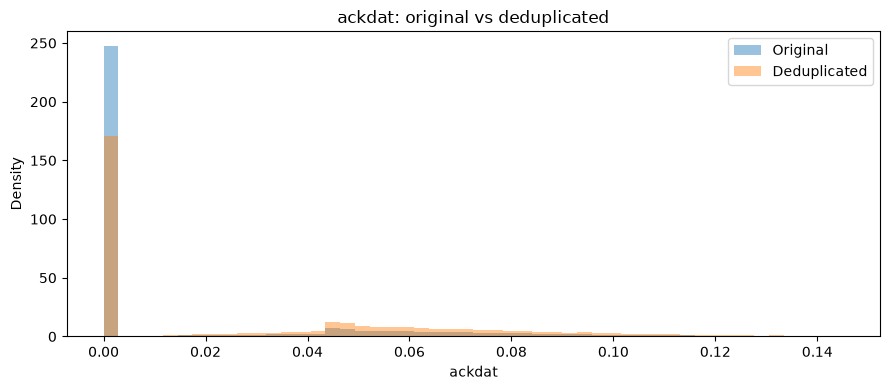

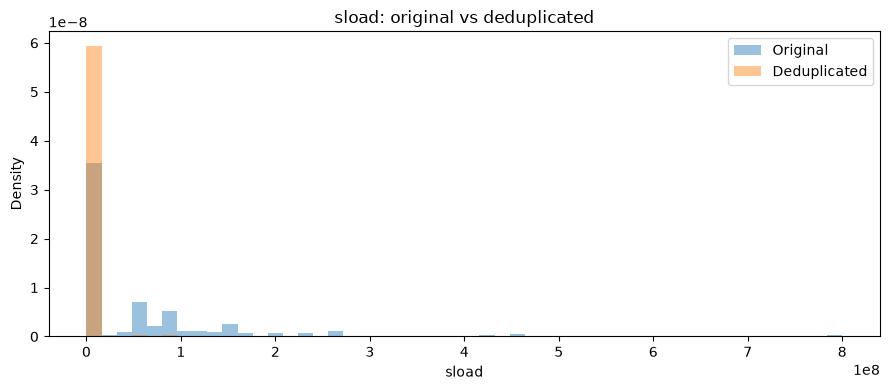

In [35]:
selected_compare_features = (
    corr_compare
    .sort_values("abs_change", ascending=False)
    .head(4)
    .index
    .tolist()
)

for col in selected_compare_features:
    fig, ax = plt.subplots(figsize=(9, 4))

    orig = train[col]
    dedup = train_dedup[col]

    # Чтобы очень длинные хвосты не уничтожали масштаб,
    # ограничиваем визуализацию 99-м перцентилем original train.
    upper = orig.quantile(0.99)

    orig_plot = orig[orig <= upper]
    dedup_plot = dedup[dedup <= upper]

    ax.hist(
        orig_plot,
        bins=50,
        density=True,
        alpha=0.45,
        label="Original",
    )
    ax.hist(
        dedup_plot,
        bins=50,
        density=True,
        alpha=0.45,
        label="Deduplicated",
    )

    ax.set_title(f"{col}: original vs deduplicated")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
    ax.legend()
    plt.tight_layout()
    plt.show()

### Вывод по сравнению Original и Deduplicated

Deduplication меняет не только количество строк, но и саму статистическую структуру данных.

**Размер:** binary-safe версия сокращает train с 175 341 до 91 839 строк, test - с 82 332 до 48 109.

**Баланс:** в train `Attack` уменьшается с 68.06% до 47.04%, а `Normal` увеличивается до 52.96%. Особенно сильный эффект наблюдается у `Generic`: 22.81% к 1.73%. Это показывает, что этот класс состоит из большого числа дубликатов.

**Описательные статистики:** после deduplication заметно меняются средние и медианы. Например, среднее `dload` растёт примерно с 671 тыс. до 1.27 млн, тогда как среднее `rate` падает примерно с 95.4 тыс. до 13.2 тыс.. Следовательно, дубликаты существенно меняют вес отдельных областей признакового пространства.

**Связи с target:** для ряда признаков меняется даже знак Spearman correlation:

- `dinpkt`: -0.275 к 0.441
- `rate`: 0.287 к -0.401
- `ackdat`: -0.155 к 0.511
- `tcprtt`: -0.163 к 0.492
- `dur`: -0.230 к 0.370